## Customer Retention & Churn Analysis
----

### 1. Problem Statement
The objective is to analyze customer churn patterns and identify key drivers of retention.

### 2. Dataset Overview
- Source: IBM Telco Customer Churn (Kaggle)
- Records: ~7,000
- Features: Demographics, services, billing, churn status


### 3. Data Cleaning
This section handles missing values, data types, and feature preparation.

----

In [1]:
# Basic libraries needed for EDA
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [2]:
# Churn Dataset
df = pd.read_csv("Telco-Customer-Churn.csv")
df.head()


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df.shape

(7043, 21)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [6]:
df.isnull().sum().head()

customerID       0
gender           0
SeniorCitizen    0
Partner          0
Dependents       0
dtype: int64

In [7]:
# Dropping customerID since it doesn't add predictive value
df = df.drop("customerID", axis=1)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [8]:
# TotalCharges is stored as object due to blanks, converting to numeric
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [9]:
# Filled missing values
df["TotalCharges"].fillna(df["TotalCharges"].median(), inplace=True)
df.isnull().sum().head()

gender           0
SeniorCitizen    0
Partner          0
Dependents       0
tenure           0
dtype: int64

In [10]:
# Encoding churn target (Yes=1, No=0)
df["ChurnFlag"] = df["Churn"].apply(lambda x: 1 if x == "Yes" else 0)
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,ChurnFlag
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,No,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1


In [11]:
# Feature engineering

# Binary churn flag
df["ChurnFlag"] = df["Churn"].map({"Yes": 1, "No": 0})

# Tenure buckets (useful for Power BI)
df["TenureGroup"] = pd.cut(
    df["tenure"],
    bins=[0, 12, 24, 36, 48, 60, 72],
    labels=["0-1 yr","1-2 yr","2-3 yr","3-4 yr","4-5 yr","5+ yr"]
)


In [12]:
# Saved cleaned data to a new CSV file
df.to_csv("cleaned_churn_data.csv", index=False)

### Why the Dataset Was Exported Before EDA

Before starting detailed exploratory data analysis (EDA) in Python, the cleaned dataset was exported for use in Power BI.

This approach was chosen to:
- Enable parallel exploratory analysis using both Python and Power BI
- Leverage Python for data cleaning and feature engineering
- Use Power BI for interactive, business-focused visual exploration
- Ensure consistency in insights across tools by working from a single cleaned data source

----


### Exploratory Data Analysis (EDA)

1️⃣ Churn distribution

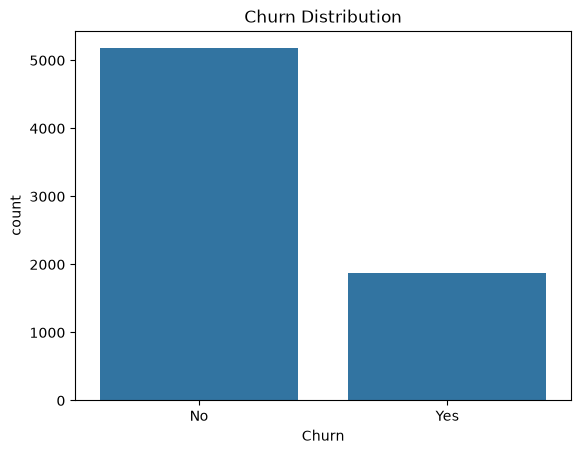

In [13]:
sns.countplot(x="Churn", data=df)
plt.title("Churn Distribution")
plt.show()

2️⃣ Churn rate

In [14]:
churn_rate = df["ChurnFlag"].mean() * 100
print(f"Churn Rate: {churn_rate:.2f}%")

Churn Rate: 26.54%


3️⃣ Tenure vs churn

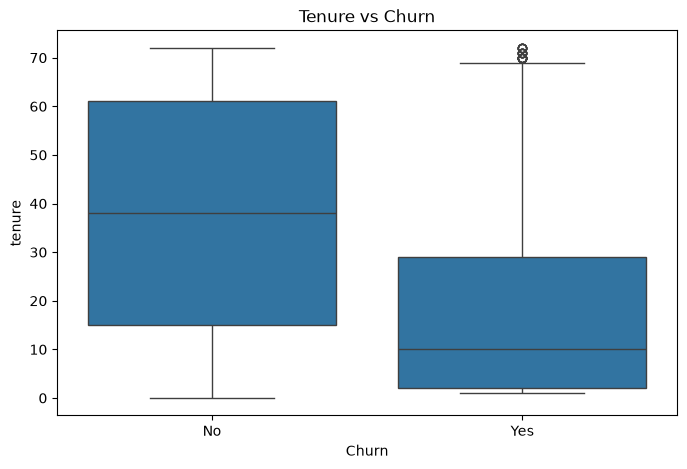

In [15]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Churn", y="tenure", data=df)
plt.title("Tenure vs Churn")
plt.show()

4️⃣ Contract type vs churn

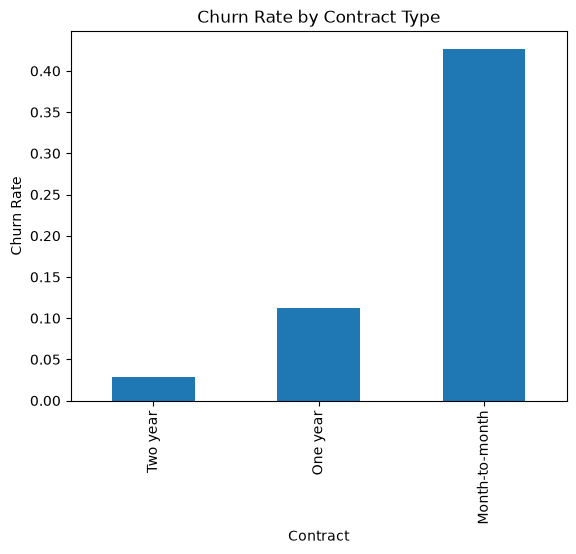

In [16]:
contract_churn = df.groupby("Contract")["ChurnFlag"].mean().sort_values()

contract_churn.plot(kind="bar")
plt.title("Churn Rate by Contract Type")
plt.ylabel("Churn Rate")
plt.show()

5️⃣ Monthly charges vs churn

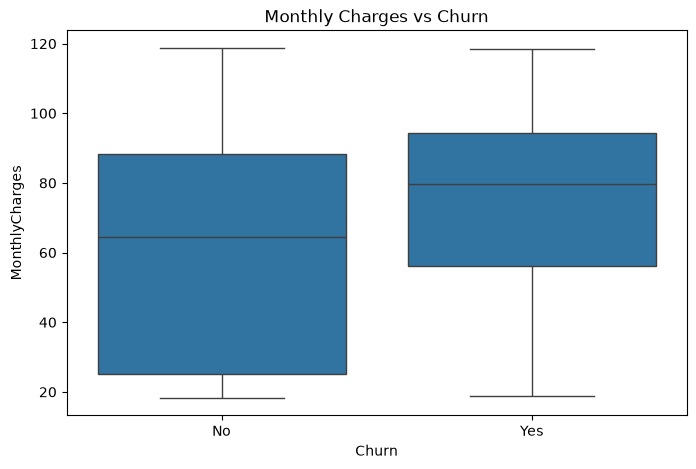

In [17]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Churn", y="MonthlyCharges", data=df)
plt.title("Monthly Charges vs Churn")
plt.show()

---
## 6. Machine Learning Preprocessing Pipeline (Scikit-Learn)
### Preventing Data Leakage
- Split dataset into **Train** and **Test** sets *before* fitting any scalers or encoders.
- Use `ColumnTransformer` + `Pipeline`:
  - Numerical features: `SimpleImputer(strategy="median")` + `StandardScaler()`
  - Categorical features: `SimpleImputer(strategy="most_frequent")` + `OneHotEncoder(drop="first")`
- Use `stratify=y` to preserve the ~73:27 class distribution.

In [18]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# 1. Prepare raw feature matrix X and target y
drop_cols = [c for c in ["Churn", "ChurnFlag", "TenureGroup", "customerID"] if c in df.columns]
X = df.drop(columns=drop_cols)
y = df["Churn"].map({"Yes": 1, "No": 0})

# 2. Stratified Train-Test Split (Strictly avoiding Data Leakage)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Identify feature types
numeric_features = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_features = [col for col in X.columns if col not in numeric_features]

# 4. Define Scikit-Learn Transformers
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# 5. Fit on X_train only, transform both train and test
X_train_proc = preprocessor.fit_transform(X_train)
X_test_proc = preprocessor.transform(X_test)

# Get engineered feature names for explainability
cat_cols_encoded = preprocessor.named_transformers_["cat"].named_steps["onehot"].get_feature_names_out(categorical_features)
all_feature_names = numeric_features + list(cat_cols_encoded)

print("Scikit-Learn Preprocessing Pipeline Completed Successfully!")
print(f"X_train shape: {X_train_proc.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test_proc.shape}, y_test shape: {y_test.shape}")
print(f"Total features after one-hot encoding: {len(all_feature_names)}")


Scikit-Learn Preprocessing Pipeline Completed Successfully!
X_train shape: (5634, 30), y_train shape: (5634,)
X_test shape: (1409, 30), y_test shape: (1409,)
Total features after one-hot encoding: 30


---
## 7. Model Training & Evaluation (Decision Tree & Random Forest)
### Classification & Metric Analysis
- **Decision Tree Classifier**: Interpretable baseline with pruning (`max_depth=5`) to prevent overfitting.
- **Random Forest Classifier**: Ensemble model reducing variance, with `class_weight="balanced"` to address class imbalance.
- **Evaluation Metrics**: Precision, Recall, F1-score, ROC-AUC, and Confusion Matrix.


--- MODEL PERFORMANCE COMPARISON ---
      Metric  Decision Tree  Random Forest
0   Accuracy         0.7303         0.7473
1  Precision         0.4951         0.5157
2     Recall         0.8075         0.7914
3   F1-Score         0.6138         0.6245
4    ROC-AUC         0.8298         0.8437


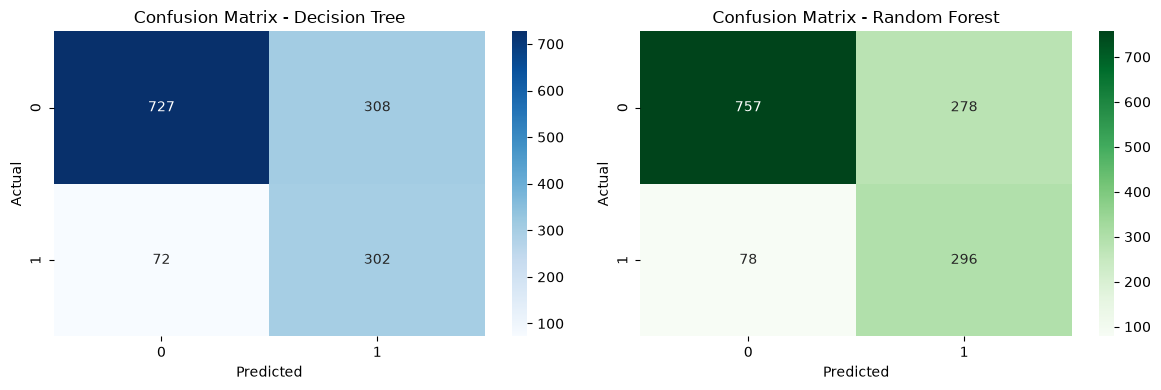

In [19]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)

# 1. Train Decision Tree (Pruned to prevent overfitting)
dt_model = DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42, class_weight="balanced")
dt_model.fit(X_train_proc, y_train)
y_pred_dt = dt_model.predict(X_test_proc)
y_proba_dt = dt_model.predict_proba(X_test_proc)[:, 1]

# 2. Train Random Forest (Ensemble with balanced weights)
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, min_samples_split=10, random_state=42, class_weight="balanced", n_jobs=-1)
rf_model.fit(X_train_proc, y_train)
y_pred_rf = rf_model.predict(X_test_proc)
y_proba_rf = rf_model.predict_proba(X_test_proc)[:, 1]

# 3. Model Comparison Table
results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
    "Decision Tree": [
        accuracy_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_dt),
        roc_auc_score(y_test, y_proba_dt)
    ],
    "Random Forest": [
        accuracy_score(y_test, y_pred_rf),
        precision_score(y_test, y_pred_rf),
        recall_score(y_test, y_pred_rf),
        f1_score(y_test, y_pred_rf),
        roc_auc_score(y_test, y_proba_rf)
    ]
})
print("\n--- MODEL PERFORMANCE COMPARISON ---")
print(results.round(4))

# 4. Confusion Matrix Visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Confusion Matrix - Decision Tree")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Confusion Matrix - Random Forest")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")
plt.tight_layout()
plt.show()


---
## 7.1. 3-Fold Stratified Cross-Validation (Model Robustness & Generalization)
To rigorously validate model stability across multiple data subsets (3 folds / sets):
- We use `StratifiedKFold(n_splits=3, shuffle=True, random_state=42)`.
- Preprocessing transformers are nested inside `Pipeline` so imputation & scaling are re-fitted on each training fold independently (Zero Leakage).
- Evaluates mean score and standard deviation across all 3 sets for ROC-AUC, Recall, Precision, F1, and Accuracy.

In [20]:
from sklearn.model_selection import StratifiedKFold, cross_validate

# Define 3-Fold Stratified Splitter (3 Sets)
skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Build Pipelines for CV
rf_cv_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(n_estimators=150, max_depth=9, min_samples_split=8, random_state=42, class_weight="balanced", n_jobs=-1))
])

dt_cv_pipe = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", DecisionTreeClassifier(max_depth=5, min_samples_leaf=20, random_state=42, class_weight="balanced"))
])

scoring_metrics = ["roc_auc", "recall", "precision", "f1", "accuracy"]

# Perform 3-Fold Cross-Validation
cv_results_rf = cross_validate(rf_cv_pipe, X, y, cv=skf, scoring=scoring_metrics)
cv_results_dt = cross_validate(dt_cv_pipe, X, y, cv=skf, scoring=scoring_metrics)

# Aggregate 3-Set Summary
cv_comparison = pd.DataFrame({
    "Metric": ["ROC-AUC", "Recall", "Precision", "F1-Score", "Accuracy"],
    "Random Forest (Mean +/- Std)": [
        f"{cv_results_rf['test_roc_auc'].mean():.4f} +/- {cv_results_rf['test_roc_auc'].std():.4f}",
        f"{cv_results_rf['test_recall'].mean():.4f} +/- {cv_results_rf['test_recall'].std():.4f}",
        f"{cv_results_rf['test_precision'].mean():.4f} +/- {cv_results_rf['test_precision'].std():.4f}",
        f"{cv_results_rf['test_f1'].mean():.4f} +/- {cv_results_rf['test_f1'].std():.4f}",
        f"{cv_results_rf['test_accuracy'].mean():.4f} +/- {cv_results_rf['test_accuracy'].std():.4f}"
    ],
    "Decision Tree (Mean +/- Std)": [
        f"{cv_results_dt['test_roc_auc'].mean():.4f} +/- {cv_results_dt['test_roc_auc'].std():.4f}",
        f"{cv_results_dt['test_recall'].mean():.4f} +/- {cv_results_dt['test_recall'].std():.4f}",
        f"{cv_results_dt['test_precision'].mean():.4f} +/- {cv_results_dt['test_precision'].std():.4f}",
        f"{cv_results_dt['test_f1'].mean():.4f} +/- {cv_results_dt['test_f1'].std():.4f}",
        f"{cv_results_dt['test_accuracy'].mean():.4f} +/- {cv_results_dt['test_accuracy'].std():.4f}"
    ]
})

print("--- 3-FOLD STRATIFIED CROSS-VALIDATION RESULTS (3 SETS) ---")
print(cv_comparison.to_string(index=False))


--- 3-FOLD STRATIFIED CROSS-VALIDATION RESULTS (3 SETS) ---
   Metric Random Forest (Mean +/- Std) Decision Tree (Mean +/- Std)
  ROC-AUC            0.8448 +/- 0.0070            0.8287 +/- 0.0057
   Recall            0.7758 +/- 0.0207            0.8026 +/- 0.0237
Precision            0.5378 +/- 0.0016            0.4934 +/- 0.0137
 F1-Score            0.6352 +/- 0.0073            0.6106 +/- 0.0041
 Accuracy            0.7636 +/- 0.0015            0.7282 +/- 0.0119


---
## 8. Customer Segmentation via K-Means Clustering
### Unsupervised Grouping
- Segments customers into distinct behavioral personas using tenure, charges, and contract commitment.
- Uses Elbow Method and Silhouette Analysis to evaluate clusters.
- Enables proactive, tailored business retention offers for each persona.

In [21]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Use the scaled numerical features for behavioral clustering
num_data = X_train_proc[:, :3] # tenure, MonthlyCharges, TotalCharges

# Fit K-Means with 3 distinct clusters (e.g., Low-Tenure Budget, High-Value Loyal, Medium Risk)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(num_data)
sil_score = silhouette_score(num_data, clusters)

print(f"K-Means (k=3) Silhouette Score: {sil_score:.3f}")

# Analyze Cluster Characteristics
train_analysis = X_train[["tenure", "MonthlyCharges", "TotalCharges"]].copy()
train_analysis["Cluster"] = clusters
train_analysis["Churn"] = y_train.values
print("\n--- CUSTOMER SEGMENT PROFILES ---")
print(train_analysis.groupby("Cluster").agg({
    "tenure": "mean",
    "MonthlyCharges": "mean",
    "TotalCharges": "mean",
    "Churn": ["mean", "count"]
}).round(2))


K-Means (k=3) Silhouette Score: 0.451

--- CUSTOMER SEGMENT PROFILES ---
        tenure MonthlyCharges TotalCharges Churn      
          mean           mean         mean  mean count
Cluster                                               
0        28.95          26.48       788.98  0.12  1713
1        13.34          75.10      1040.46  0.47  2129
2        58.61          89.59      5242.80  0.16  1792


---
## 9. Model Persistence & Production Artifacts
### Saving End-to-End Pipeline
We persist the full Scikit-Learn pipeline (transformers + classifier) using `joblib` so that:
1. It can be directly loaded into production APIs or a Streamlit web app.
2. New unseen single-row inputs are automatically transformed with identical preprocessing rules without code duplication.

In [22]:
import os
import joblib

# Ensure models directory exists
os.makedirs("../models", exist_ok=True)

# 1. Full pipeline combining preprocessor and trained Random Forest
production_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", rf_model)
])

# 2. Save models and metadata
joblib.dump(production_pipeline, "../models/churn_pipeline.joblib")
joblib.dump({"kmeans": kmeans}, "../models/customer_clustering.joblib")
joblib.dump({
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "all_features": list(X.columns)
}, "../models/feature_metadata.joblib")

print("Production models and pipelines successfully persisted to ../models/")


Production models and pipelines successfully persisted to ../models/
